In [38]:
%pip install pandas numpy matplotlib seaborn scikit-learn nltk datasets

Note: you may need to restart the kernel to use updated packages.


In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

In [40]:
dataset = load_dataset("cardiffnlp/tweet_eval", "emotion")

dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3257
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1421
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 374
    })
})

In [41]:
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Training shape: (3257, 2)
Validation shape: (374, 2)
Test shape: (1421, 2)


In [42]:
train_df.head()

,text,label
0,“Worry is a down payment on a problem you may ...,2
1,My roommate: it's okay that we can't spell bec...,0
2,No but that's so cute. Atsu was probably shy a...,1
3,Rooneys fucking untouchable isn't he? Been fuc...,0
4,it's pretty depressing when u hit pan on ur fa...,3


In [43]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3257 entries, 0 to 3256
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    3257 non-null   object
 1   label   3257 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 51.0+ KB


In [44]:
print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:")
print(train_df.duplicated().sum())

Missing values:
text     0
label    0
dtype: int64

Duplicate rows:
25


In [45]:
train_df.drop_duplicates()

,text,label
0,“Worry is a down payment on a problem you may ...,2
1,My roommate: it's okay that we can't spell bec...,0
2,No but that's so cute. Atsu was probably shy a...,1
3,Rooneys fucking untouchable isn't he? Been fuc...,0
4,it's pretty depressing when u hit pan on ur fa...,3
...,...,...
3252,I get discouraged because I try for 5 fucking ...,3
3253,The @user are in contention and hosting @user ...,3
3254,@user @user @user @user @user as a fellow UP g...,0
3255,You have a #problem? Yes! Can you do #somethin...,0


In [46]:
label_names = {
    0: "anger",
    1: "joy",
    2: "optimism",
    3: "sadness"
}

In [47]:
for df in [train_df, val_df, test_df]:
    df["emotion"] = df["label"].map(label_names)

train_df.head()

,text,label,emotion
0,“Worry is a down payment on a problem you may ...,2,optimism
1,My roommate: it's okay that we can't spell bec...,0,anger
2,No but that's so cute. Atsu was probably shy a...,1,joy
3,Rooneys fucking untouchable isn't he? Been fuc...,0,anger
4,it's pretty depressing when u hit pan on ur fa...,3,sadness


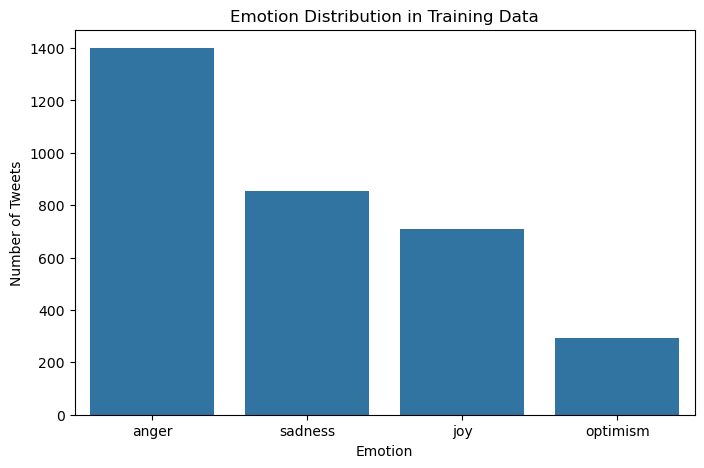

In [48]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="emotion",
    order=train_df["emotion"].value_counts().index
)

plt.title("Emotion Distribution in Training Data")
plt.xlabel("Emotion")
plt.ylabel("Number of Tweets")

plt.show()

In [49]:
class_distribution = train_df["emotion"].value_counts()

class_percentage = (
    train_df["emotion"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Class Counts:")
print(class_distribution)

print("\nClass Percentages:")
print(class_percentage)

Class Counts:
emotion
anger       1400
sadness      855
joy          708
optimism     294
Name: count, dtype: int64

Class Percentages:
emotion
anger       42.98
sadness     26.25
joy         21.74
optimism     9.03
Name: proportion, dtype: float64


In [50]:
train_df["text_length"] = train_df["text"].apply(len)
train_df["word_count"] = train_df["text"].apply(lambda x: len(x.split()))

train_df[["text_length", "word_count"]].describe()

,text_length,word_count
count,3257.000000,3257.000000
mean,91.272029,16.166718
std,36.536134,6.685881
min,6.000000,1.000000
25%,60.000000,11.000000
50%,96.000000,17.000000
75%,126.000000,22.000000
max,160.000000,33.000000


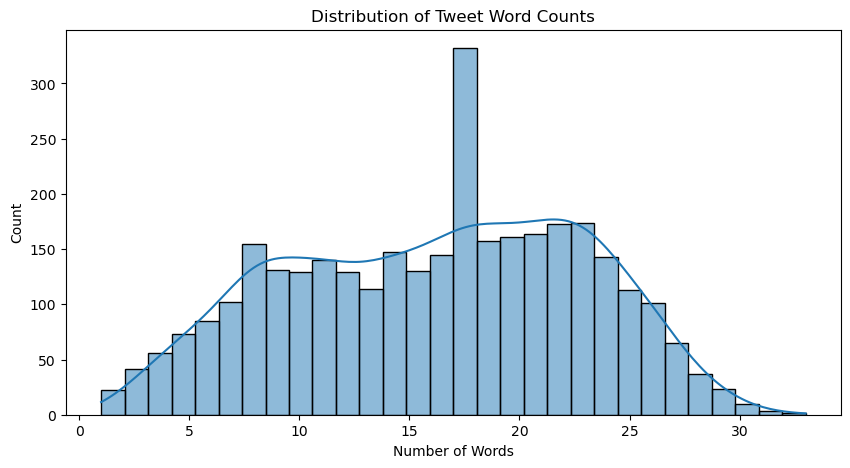

In [51]:
plt.figure(figsize=(10, 5))

sns.histplot(train_df["word_count"], bins=30, kde=True)

plt.title("Distribution of Tweet Word Counts")
plt.xlabel("Number of Words")

plt.show()

In [52]:
for emotion in train_df["emotion"].unique():
    
    print(f"\n{'=' * 50}")
    print(f"Emotion: {emotion.upper()}")
    print(f"{'=' * 50}")
    
    examples = train_df[train_df["emotion"] == emotion]["text"].head(3)
    
    for i, text in enumerate(examples, 1):
        print(f"{i}. {text}")


Emotion: OPTIMISM
1. “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry
2. I saved him after ordering him to risk his life. I didn't panic but stayed calm and rescued him.
3. @user Uggh that's really horrible. You're not a bad person by any stretch of the imagination. I hope this person realizes that.

Emotion: ANGER
1. My roommate: it's okay that we can't spell because we have autocorrect. #terrible #firstworldprobs
2. Rooneys fucking untouchable isn't he? Been fucking dreadful again, depay has looked decent(ish)tonight
3. @user but your pussy was weak from what I heard so stfu up to me bitch . You got to threaten him that your pregnant .

Emotion: JOY
1. No but that's so cute. Atsu was probably shy about photos before but cherry helped her out uwu
2. Tiller and breezy should do a collab album. Rapping and singing prolly be fire
3. angel delight is my everything

Emotion: SADNESS
1. it's pretty depressing when u hit pan on ur favo

In [53]:
# See available splits and their sizes
print(dataset)

# View the first rows of the training split
display(dataset["train"].to_pandas().head())

# View a random sample
display(dataset["train"].to_pandas().sample(5, random_state=42))

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3257
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1421
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 374
    })
})


,text,label
0,“Worry is a down payment on a problem you may ...,2
1,My roommate: it's okay that we can't spell bec...,0
2,No but that's so cute. Atsu was probably shy a...,1
3,Rooneys fucking untouchable isn't he? Been fuc...,0
4,it's pretty depressing when u hit pan on ur fa...,3


,text,label
2829,Cuz even the bible talks about the son coming ...,0
134,Need advice on how to get out of this rut!!!! ...,2
2299,"@user Don't ask, you don't get. Apologies if I...",0
1610,#Terencecutcher #Tulsa the man onthe helicopte...,3
990,@user So I worry about emphasis on 'keeping fa...,2
